
# Árvore de Decisão — Titanic (Tech Challenge Fase 3)

Este notebook treina e avalia um modelo **DecisionTreeClassifier** para prever a sobrevivência no Titanic,
mantendo a **mesma ordem de *features*** usada na aplicação (`predict_app.py`), para evitar erros na hora de servir o modelo.

**Fluxo:** Carregar dados → Pré-processar → Treinar (baseline e *tuning*) → Avaliar → Salvar artefato (`modelo/modelo_arvore.pkl`) e métricas.


In [2]:
pip install -q numpy pandas matplotlib seaborn scikit-learn joblib ipykernel

Note: you may need to restart the kernel to use updated packages.


In [1]:

import os, json, sqlite3, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
import joblib

warnings.filterwarnings("ignore")

# Pastas e arquivos do projeto (ajuste se necessário ao seu layout local)
RAW_CSV = Path('FASE3_TC/data/RAW/Titanic-Dataset.csv')
ALT_RAW_CSV = Path('data/RAW/Titanic-Dataset.csv')
DB_SQLITE = Path('FASE3_TC/data/PROCESSED/titanic.db')
ALT_DB_SQLITE = Path('data/PROCESSED/titanic.db')

# Onde salvar artefatos e outputs
Path('modelo').mkdir(exist_ok=True, parents=True)
Path('outputs').mkdir(exist_ok=True, parents=True)

# **IMPORTANTE:** ORDEM das features deve bater com a esperada pelo app
FEATURES = ['Pclass','Age','SibSp','Parch','Fare','Sex_male','Embarked_C','Embarked_Q','Embarked_S']
TARGET = 'Survived'
RANDOM_STATE = 42


In [ ]:

def load_titanic_dataframe() -> pd.DataFrame:
    """Carrega o dataset do SQLite (preferencial) ou do CSV (fallback) de forma robusta."""
    if DB_SQLITE.exists():
        src = DB_SQLITE
    elif ALT_DB_SQLITE.exists():
        src = ALT_DB_SQLITE
    elif RAW_CSV.exists():
        src = RAW_CSV
    elif ALT_RAW_CSV.exists():
        src = ALT_RAW_CSV
    else:
        raise FileNotFoundError('Não encontrei DB nem CSV. Garanta que o main.py rodou ou coloque o CSV em data/RAW.')

    if src.suffix.lower() == '.db':
        with sqlite3.connect(src) as conn:
            df = pd.read_sql('SELECT * FROM titanic', conn)
    else:
        df = pd.read_csv(src)
    print(f'Dados carregados de: {src} | shape={df.shape}')
    return df

def preprocess_for_app(df: pd.DataFrame) -> pd.DataFrame:
    """Prepara o dataset garantindo as **mesmas** features do app, na **mesma ordem**.
    - Imputa faltantes (Age, Fare por mediana; Embarked e Sex por moda)
    - Cria Sex_male e dummies Embarked_C/Q/S
    - Seleciona FEATURES + TARGET
    """
    req_cols = {'Pclass','Age','SibSp','Parch','Fare','Sex','Embarked'}
    lower = {c.lower() for c in df.columns}
    if not {c.lower() for c in req_cols}.issubset(lower):
        raise ValueError(f'Colunas obrigatórias ausentes. Preciso de {req_cols}, mas tenho {set(df.columns)}')

    d = df.copy()

    # imputação simples
    if 'Age' in d.columns:
        d['Age'] = d['Age'].fillna(d['Age'].median())
    if 'Fare' in d.columns:
        d['Fare'] = d['Fare'].fillna(d['Fare'].median())
    if 'Embarked' in d.columns:
        d['Embarked'] = d['Embarked'].fillna(d['Embarked'].mode().iloc[0])
    if 'Sex' in d.columns:
        d['Sex'] = d['Sex'].fillna(d['Sex'].mode().iloc[0])

    # engenharia de variáveis alinhada ao app
    d['Sex_male'] = (d['Sex'].astype(str).str.lower() == 'male').astype(int)
    for port in ['C','Q','S']:
        d[f'Embarked_{port}'] = (d['Embarked'].astype(str).str.upper() == port).astype(int)

    # garantir tipos numéricos
    for c in FEATURES:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    d[FEATURES] = d[FEATURES].fillna(0)

    # alvo
    if TARGET not in d.columns:
        # tenta encontrar 'survived' em qualquer capitalização
        candidates = [c for c in d.columns if c.lower() == 'survived']
        if candidates:
            d = d.rename(columns={candidates[0]: TARGET})
        else:
            raise ValueError('Coluna alvo Survived não encontrada.')

    d = d.dropna(subset=[TARGET]).copy()
    d[TARGET] = d[TARGET].astype(int)

    # mantém só as colunas necessárias
    out = d[FEATURES + [TARGET]].copy()
    print('Colunas finais:', list(out.columns))
    print('Shape final:', out.shape)
    return out


In [6]:

df_raw = load_titanic_dataframe()
df = preprocess_for_app(df_raw)

X = df[FEATURES].values
y = df[TARGET].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

X_train.shape, X_test.shape, y_train.mean(), y_test.mean()

df

✔ Dados carregados de: data\PROCESSED\titanic.db | shape=(891, 12)
Colunas finais: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Survived']
Shape final: (891, 10)


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Survived
0,3,22.0,1,0,7.2500,1,0,0,1,0
1,1,38.0,1,0,71.2833,0,1,0,0,1
2,3,26.0,0,0,7.9250,0,0,0,1,1
3,1,35.0,1,0,53.1000,0,0,0,1,1
4,3,35.0,0,0,8.0500,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
886,2,27.0,0,0,13.0000,1,0,0,1,0
887,1,19.0,0,0,30.0000,0,0,0,1,1
888,3,28.0,1,2,23.4500,0,0,0,1,0
889,1,26.0,0,0,30.0000,1,1,0,0,1


In [7]:

tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced'  # ajuda quando classes são desbalanceadas
)
tree.fit(X_train, y_train)

y_prob = tree.predict_proba(X_test)[:,1]
y_pred = (y_prob >= 0.5).astype(int)

print('Baseline DecisionTree')
print('ROC AUC:', roc_auc_score(y_test, y_prob))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))
print('F1:', f1_score(y_test, y_pred, zero_division=0))
print('\nClassification Report:\n', classification_report(y_test, y_pred, zero_division=0))


Baseline DecisionTree
ROC AUC: 0.7774703557312254
Accuracy: 0.7932960893854749
Precision: 0.7424242424242424
Recall: 0.7101449275362319
F1: 0.725925925925926

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.85      0.83       110
           1       0.74      0.71      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



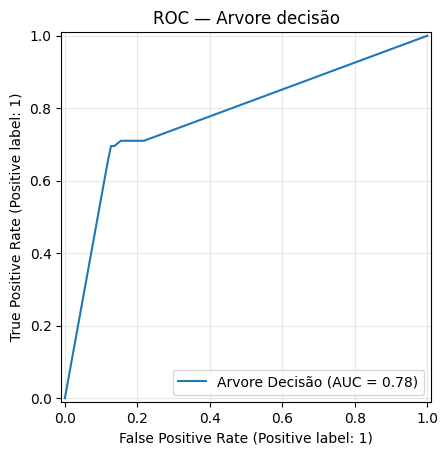

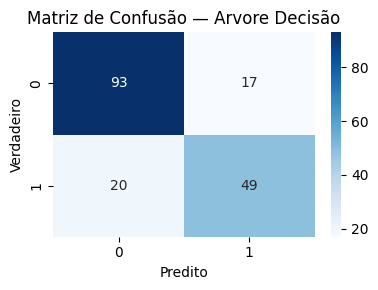

In [8]:

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob, name='Arvore Decisão')
plt.title('ROC — Arvore decisão')
plt.grid(True, alpha=.3)
plt.show()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão — Arvore Decisão')
plt.xlabel('Predito'); plt.ylabel('Verdadeiro')
plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path
import joblib, json
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

Path("modelo").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

joblib.dump(tree, "modelo/modelo_arvore.pkl")  # mantém o app funcionando

metrics = {
    "model": "DecisionTree (baseline)",
    "features_order": ["Pclass","Age","SibSp","Parch","Fare","Sex_male","Embarked_C","Embarked_Q","Embarked_S"],
    "test": {
        "roc_auc": float(roc_auc_score(y_test, y_prob)),
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
    }
}
with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("Modelo final salvo em modelo/modelo_final.pkl e métricas em outputs/metrics.json")

Modelo final salvo em modelo/modelo_final.pkl e métricas em outputs/metrics.json
